# P4a — Embeddings FastText français côté cible (fongbé → français)
Architectures A2 (BiLSTM+attention) et A3 (BiGRU+attention).

**Avant de lancer (Kaggle)** : Settings → Accelerator **GPU**, Internet **On** (pour télécharger FastText). Add Input : un Dataset contenant `config.yaml`, `spm_fr.model`, `train.csv`, `val.csv` (et `spm_fon.model` si l'équipe en a un). Le test n'est jamais utilisé.

## [0] Installation — à lancer UNE fois dans une cellule Colab

In [7]:
!pip install -U -q pip setuptools wheel
!pip install -q sentencepiece sacrebleu pyyaml fasttext
!wget -nc -q -P /content https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.fr.300.bin.gz
!gunzip -f /content/cc.fr.300.bin.gz

## [1] Réglages et imports

In [13]:
from google.colab import files
import os

print("Veuillez téléverser vos fichiers (config.yaml, train.csv, val.csv, spm_fr.model, spm_fon.model si disponible) :")
uploaded = files.upload()

# Facultatif : création d'un lien symbolique si le code cherche dans /kaggle/working
os.makedirs('/kaggle/working', exist_ok=True)
for filename in uploaded.keys():
    dest_path = os.path.join('/kaggle/working', filename)
    if not os.path.exists(dest_path):
        os.symlink(os.path.abspath(filename), dest_path)
        print(f"Lien créé vers /kaggle/working/{filename}")

Veuillez téléverser vos fichiers (config.yaml, train.csv, val.csv, spm_fr.model, spm_fon.model si disponible) :


Saving spm_fr.vocab to spm_fr.vocab
Saving spm_fr.model to spm_fr.model
Lien créé vers /kaggle/working/spm_fr.vocab
Lien créé vers /kaggle/working/spm_fr.model


In [11]:
import os, time, json, random, copy
from collections import Counter

import numpy as np
import pandas as pd
import yaml
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import sentencepiece as spm
from sacrebleu.metrics import BLEU, CHRF

OUT_DIR = "/content/p4a_outputs"     # Adapté pour Colab
FT_PATH = "/content/cc.fr.300.bin"   # Adapté pour Colab


def find_file(name):
    """Cherche un fichier par son nom dans le répertoire courant de Colab "." et ses sous-dossiers."""
    for root in (".", "/content"):
        for d, _, files in os.walk(root):
            if name in files:
                return os.path.join(d, name)
    raise FileNotFoundError(f"{name} introuvable : téléversez-le dans la cellule d'import Colab.")

SRC_COL = None                              # nom de la colonne fongbé  (None = détection automatique)
TGT_COL = None                              # nom de la colonne français (None = détection automatique)

# Expériences : (architecture, init des embeddings cible, mode)
#   init : "random" (contrôle local), "piece" (FastText sur le sous-mot), "avgwords" (moyenne des mots contenant le sous-mot)
#   mode : "finetune" (embeddings entraînables, lr x EMB_LR_MULT) ou "frozen" (gelés)
EXPERIMENTS = [
    ("A2", "piece", "finetune"),
    ("A3", "piece", "finetune"),
    ("A2", "piece", "frozen"),
    ("A2", "random", "finetune"),     # contrôle local pour comparer (P0 de Wadoud reste la référence officielle)
    # ("A2", "avgwords", "finetune"),
    # ("A3", "random", "finetune"),
]
EMB_LR_MULT = 0.1      # multiplicateur du lr pour les embeddings cible en mode finetune
EMB_STD = 1.0          # écart-type cible de la matrice FastText (comme nn.Embedding par défaut)

os.makedirs(OUT_DIR, exist_ok=True)
CFG = yaml.safe_load(open(find_file("config.yaml"), encoding="utf-8"))
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev)

PAD, UNK, SOS, EOS = (CFG["tokenizer"][k] for k in ("pad_id", "unk_id", "sos_id", "eos_id"))
MAX_SRC, MAX_TGT = CFG["tokenizer"]["max_src_len"], CFG["tokenizer"]["max_tgt_len"]
EMB, HID, DROP = CFG["model"]["emb_dim"], CFG["model"]["hid_dim"], CFG["model"]["dropout"]
T = CFG["train"]


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda


## [2] Données et tokenizers

In [14]:
def detect_cols(df):
    cols = list(df.columns)
    s = SRC_COL or next((c for c in cols if any(k in c.lower() for k in ("fon", "src", "source"))), None)
    t = TGT_COL or next((c for c in cols if any(k in c.lower() for k in ("fr", "tgt", "target", "french", "franc"))), None)
    if s is None or t is None or s == t:
        raise ValueError(f"Colonnes non détectées parmi {cols} : renseigne SRC_COL et TGT_COL.")
    return s, t


def read_split(path):
    df = pd.read_csv(path)
    s, t = detect_cols(df)
    df = df[[s, t]].dropna().astype(str)
    print(f"{os.path.basename(path)} : {len(df)} paires | src='{s}' tgt='{t}'")
    return df[s].str.strip().tolist(), df[t].str.strip().tolist()


tr_src, tr_tgt = read_split(find_file("train.csv"))
va_src, va_tgt = read_split(find_file("val.csv"))
print("exemple :", tr_src[0], "->", tr_tgt[0])

sp_fr = spm.SentencePieceProcessor(model_file=find_file("spm_fr.model"))
assert (sp_fr.pad_id(), sp_fr.unk_id(), sp_fr.bos_id(), sp_fr.eos_id()) == (PAD, UNK, SOS, EOS), "ids spéciaux spm_fr != config"

try:
    fon_model = find_file("spm_fon.model")       # idéalement celui de l'équipe : mêmes tokenizers pour tous
except FileNotFoundError:
    fon_model = os.path.join(OUT_DIR, "spm_fon.model")
    print("spm_fon.model absent : entraînement d'un tokenizer fongbé sur le train")
if not os.path.exists(fon_model):
    with open("/tmp/fon_train.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(tr_src))
    spm.SentencePieceTrainer.train(
        input="/tmp/fon_train.txt", model_prefix=os.path.join(OUT_DIR, "spm_fon"),
        vocab_size=CFG["tokenizer"]["fon_vocab"], model_type="unigram", character_coverage=1.0,
        pad_id=PAD, unk_id=UNK, bos_id=SOS, eos_id=EOS)
sp_fon = spm.SentencePieceProcessor(model_file=fon_model)
V_SRC, V_TGT = sp_fon.get_piece_size(), sp_fr.get_piece_size()
print("vocab src/tgt :", V_SRC, V_TGT)


def build(src, tgt, train):
    data, dropped = [], 0
    S, Tg = sp_fon.encode(src), sp_fr.encode(tgt)
    for s, t in zip(S, Tg):
        if train and (len(s) > MAX_SRC or len(t) > MAX_TGT - 1):
            dropped += 1; continue
        s = s[:MAX_SRC] or [UNK]
        t = t[:MAX_TGT - 1]
        data.append((s, [SOS] + t, t + [EOS]))
    if train:
        print(f"train : {dropped} paires écartées (trop longues)")
    return data


train_data = build(tr_src, tr_tgt, True)
val_data = build(va_src, va_tgt, False)


def collate(data, idx):
    b = [data[i] for i in idx]
    ls = torch.tensor([len(x[0]) for x in b])
    S = torch.full((len(b), int(ls.max())), PAD, dtype=torch.long)
    Ti = torch.full((len(b), max(len(x[1]) for x in b)), PAD, dtype=torch.long)
    To = torch.full_like(Ti, PAD)
    for k, (s, ti, to) in enumerate(b):
        S[k, :len(s)] = torch.tensor(s); Ti[k, :len(ti)] = torch.tensor(ti); To[k, :len(to)] = torch.tensor(to)
    return S.to(dev), ls, Ti.to(dev), To.to(dev)


def make_batches(data, bs, shuffle):
    idx = list(range(len(data)))
    if shuffle:
        random.shuffle(idx)
        batches = []
        for i in range(0, len(idx), bs * 50):          # tri par longueur dans de gros blocs -> moins de padding
            ch = sorted(idx[i:i + bs * 50], key=lambda j: len(data[j][1]))
            batches += [ch[k:k + bs] for k in range(0, len(ch), bs)]
        random.shuffle(batches)
        return batches
    idx.sort(key=lambda j: len(data[j][0]))
    return [idx[k:k + bs] for k in range(0, len(idx), bs)]

train.csv : 27730 paires | src='fon' tgt='fr'
val.csv : 2242 paires | src='fon' tgt='fr'
exemple : bo nuɖe tɛ wɛ -> et qu'est
spm_fon.model absent : entraînement d'un tokenizer fongbé sur le train
vocab src/tgt : 2000 4000
train : 116 paires écartées (trop longues)


## [3] Matrices d'embeddings FastText pour les 4000 sous-mots français

In [15]:
def fasttext_matrices():
    cache_p, cache_w = os.path.join(OUT_DIR, "emb_piece.npy"), os.path.join(OUT_DIR, "emb_avgwords.npy")
    if os.path.exists(cache_p) and os.path.exists(cache_w):
        return {"piece": np.load(cache_p), "avgwords": np.load(cache_w)}
    import fasttext
    print("chargement FastText (1-2 min, ~7 Go de RAM)...")
    ft = fasttext.load_model(FT_PATH)
    special = {PAD, UNK, SOS, EOS}
    raw_piece = np.zeros((V_TGT, ft.get_dimension()), dtype=np.float32)
    ok_piece = np.zeros(V_TGT, dtype=bool)
    for i in range(V_TGT):
        if i in special:
            continue
        p = sp_fr.id_to_piece(i).replace("\u2581", "")
        if p:                                           # "▁" seul -> pas de vecteur, init aléatoire
            raw_piece[i] = ft.get_word_vector(p); ok_piece[i] = True
    # option B : moyenne pondérée par la fréquence des mots du train contenant le sous-mot
    sums = np.zeros_like(raw_piece); wts = np.zeros(V_TGT)
    for w, c in Counter(w for s in tr_tgt for w in s.split()).items():
        v = ft.get_word_vector(w)
        for pid in set(sp_fr.encode(w)):
            if pid not in special:
                sums[pid] += c * v; wts[pid] += c
    raw_avg = raw_piece.copy(); ok_avg = ok_piece.copy()
    seen = wts > 0
    raw_avg[seen] = sums[seen] / wts[seen, None]; ok_avg |= seen
    del ft

    def finalize(raw, ok):
        X = raw[ok]
        X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
        X = X - X.mean(0, keepdims=True)
        _, _, Vt = np.linalg.svd(X, full_matrices=False)  # PCA : 300 -> EMB dimensions
        Z = X @ Vt[:EMB].T
        Z = Z / Z.std() * EMB_STD
        out = np.random.RandomState(CFG["seed"]).normal(0, EMB_STD, (V_TGT, EMB)).astype(np.float32)
        out[ok] = Z; out[PAD] = 0.0
        return out

    mats = {"piece": finalize(raw_piece, ok_piece), "avgwords": finalize(raw_avg, ok_avg)}
    np.save(cache_p, mats["piece"]); np.save(cache_w, mats["avgwords"])
    print(f"couverture : piece {ok_piece.sum()}/{V_TGT} | avgwords {ok_avg.sum()}/{V_TGT}")
    return mats


EMB_MATS = None   # chargé à la demande (seulement si une expérience en a besoin)

## [4] Modèle : A2 (LSTM) / A3 (GRU) — encodeur bidirectionnel + attention de Bahdanau

In [16]:
class Bahdanau(nn.Module):
    def __init__(self, enc_dim, dec_dim, att_dim):
        super().__init__()
        self.W_enc = nn.Linear(enc_dim, att_dim, bias=False)
        self.W_dec = nn.Linear(dec_dim, att_dim)
        self.v = nn.Linear(att_dim, 1, bias=False)

    def project(self, enc_out):
        return self.W_enc(enc_out)

    def forward(self, h, enc_out, proj, mask):
        e = self.v(torch.tanh(proj + self.W_dec(h).unsqueeze(1))).squeeze(-1)
        a = F.softmax(e.masked_fill(~mask, -1e9), dim=-1)
        return torch.bmm(a.unsqueeze(1), enc_out).squeeze(1)


class Seq2Seq(nn.Module):
    def __init__(self, arch, v_src, v_tgt):
        super().__init__()
        self.lstm = arch == "A2"
        rnn = nn.LSTM if self.lstm else nn.GRU
        cell = nn.LSTMCell if self.lstm else nn.GRUCell
        self.src_emb = nn.Embedding(v_src, EMB, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(v_tgt, EMB, padding_idx=PAD)
        self.enc = rnn(EMB, HID, num_layers=1, batch_first=True, bidirectional=True)
        self.bridge_h = nn.Linear(2 * HID, HID)
        self.bridge_c = nn.Linear(2 * HID, HID) if self.lstm else None
        self.attn = Bahdanau(2 * HID, HID, HID)
        self.cell = cell(EMB + 2 * HID, HID)
        self.out = nn.Linear(HID + 2 * HID + EMB, v_tgt)      # [état ; contexte ; embedding] -> vocab
        self.drop = nn.Dropout(DROP)

    def encode(self, src, src_len):
        mask = src != PAD
        x = self.drop(self.src_emb(src))
        packed = pack_padded_sequence(x, src_len.cpu(), batch_first=True, enforce_sorted=False)
        out, hn = self.enc(packed)
        enc_out, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))
        if self.lstm:
            h, c = hn
            state = (torch.tanh(self.bridge_h(torch.cat([h[0], h[1]], -1))),
                     torch.tanh(self.bridge_c(torch.cat([c[0], c[1]], -1))))
        else:
            state = (torch.tanh(self.bridge_h(torch.cat([hn[0], hn[1]], -1))),)
        return enc_out, mask, state, self.attn.project(enc_out)

    def step(self, y, state, enc_out, proj, mask):
        emb = self.drop(self.tgt_emb(y))
        ctx = self.attn(state[0], enc_out, proj, mask)
        inp = torch.cat([emb, ctx], -1)
        if self.lstm:
            state = self.cell(inp, state)
        else:
            state = (self.cell(inp, state[0]),)
        logits = self.out(self.drop(torch.cat([state[0], ctx, emb], -1)))
        return logits, state

    def forward(self, src, src_len, tgt_in):             # teacher forcing = 1.0
        enc_out, mask, state, proj = self.encode(src, src_len)
        outs = []
        for t in range(tgt_in.size(1)):
            lg, state = self.step(tgt_in[:, t], state, enc_out, proj, mask)
            outs.append(lg)
        return torch.stack(outs, 1)

## [5] Décodage (glouton par batch, beam search par phrase) et métriques

In [17]:
@torch.no_grad()
def greedy_batch(model, src, src_len, max_len):
    enc_out, mask, state, proj = model.encode(src, src_len)
    y = torch.full((src.size(0),), SOS, dtype=torch.long, device=dev)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=dev)
    outs = []
    for _ in range(max_len):
        lg, state = model.step(y, state, enc_out, proj, mask)
        y = lg.argmax(-1); outs.append(y); done |= y == EOS
        if done.all():
            break
    res = []
    for seq in torch.stack(outs, 1).tolist():
        res.append(seq[:seq.index(EOS)] if EOS in seq else seq)
    return res


@torch.no_grad()
def beam_one(model, src, src_len, k, max_len):
    enc_out, mask, state, _ = model.encode(src, src_len)
    enc_out, mask = enc_out.expand(k, -1, -1).contiguous(), mask.expand(k, -1).contiguous()
    state = tuple(s.expand(k, -1).contiguous() for s in state)
    proj = model.attn.project(enc_out)
    y = torch.full((k,), SOS, dtype=torch.long, device=dev)
    scores = torch.zeros(k, device=dev); scores[1:] = -1e9
    hist = torch.zeros(k, 0, dtype=torch.long, device=dev)
    finished = []
    for t in range(max_len):
        lg, state = model.step(y, state, enc_out, proj, mask)
        cand = (scores.unsqueeze(1) + F.log_softmax(lg, -1)).view(-1)
        top_s, top_i = cand.topk(k)
        beam_idx, tok = top_i // lg.size(1), top_i % lg.size(1)
        state = tuple(s[beam_idx] for s in state)
        hist = torch.cat([hist[beam_idx], tok.unsqueeze(1)], 1)
        scores, y = top_s.clone(), tok
        for i in (tok == EOS).nonzero().flatten().tolist():
            finished.append((scores[i].item() / (t + 1), hist[i, :-1].tolist()))   # normalisation par la longueur
            scores[i] = -1e9
        if len(finished) >= k:
            break
    if not finished:
        finished = [(scores[i].item() / max_len, hist[i].tolist()) for i in range(k)]
    return max(finished, key=lambda x: x[0])[1]


def translate(model, data, idx=None, method="greedy"):
    model.eval()
    idx = list(range(len(data))) if idx is None else list(idx)
    hyp = {}
    if method == "greedy":
        order = sorted(idx, key=lambda j: len(data[j][0]))
        for k in range(0, len(order), 64):
            b = order[k:k + 64]
            S, ls, _, _ = collate(data, b)
            for j, seq in zip(b, greedy_batch(model, S, ls, CFG["decode"]["max_len"])):
                hyp[j] = seq
    else:
        for j in idx:
            S, ls, _, _ = collate(data, [j])
            hyp[j] = beam_one(model, S, ls, CFG["decode"]["beam_size"], CFG["decode"]["max_len"])
    return [sp_fr.decode(hyp[j]) for j in idx]


def scores(hyps, refs):
    bleu = BLEU(tokenize=CFG["eval"]["bleu_tokenize"], lowercase=True).corpus_score(hyps, [refs]).score
    chrf = CHRF(lowercase=True).corpus_score(hyps, [refs]).score
    return bleu, chrf


@torch.no_grad()
def val_loss(model):
    model.eval()
    tot, n = 0.0, 0
    for b in make_batches(val_data, 64, False):
        S, ls, Ti, To = collate(val_data, b)
        lg = model(S, ls, Ti)
        tot += F.cross_entropy(lg.reshape(-1, lg.size(-1)), To.reshape(-1), ignore_index=PAD, reduction="sum").item()
        n += (To != PAD).sum().item()
    return tot / n


chrf_idx = random.Random(CFG["seed"]).sample(range(len(val_data)), min(T["chrf_subset"], len(val_data)))

## [6] Entraînement d'une expérience

In [20]:
def run(arch, init, mode):
    global EMB_MATS
    tag = f"{arch}_{init}_{mode}" if init != "random" else f"{arch}_random"
    out = os.path.join(OUT_DIR, tag); os.makedirs(out, exist_ok=True)
    set_seed(CFG["seed"])
    model = Seq2Seq(arch, V_SRC, V_TGT).to(dev)
    if init != "random":
        if EMB_MATS is None:
            EMB_MATS = fasttext_matrices()
        model.tgt_emb.weight.data.copy_(torch.from_numpy(EMB_MATS[init]))
    emb_params = list(model.tgt_emb.parameters())
    other = [p for n, p in model.named_parameters() if not n.startswith("tgt_emb")]
    if init != "random" and mode == "frozen":
        for p in emb_params: p.requires_grad = False
        groups = [{"params": other, "lr": T["lr"]}]
    elif init != "random":
        groups = [{"params": other, "lr": T["lr"]}, {"params": emb_params, "lr": T["lr"] * EMB_LR_MULT}]
    else:
        groups = [{"params": other + emb_params, "lr": T["lr"]}]
    opt = torch.optim.Adam(groups)
    crit = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=T["label_smoothing"])
    n_params = sum(p.numel() for p in model.parameters())
    print(f"\n=== {tag} | {n_params/1e6:.2f} M paramètres ===")

    def save(name, step, epoch, best):
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "step": step, "epoch": epoch, "best_val": best,
                    "config": {"pipeline": "P4a", "arch": arch, "init": init, "mode": mode, "seed": CFG["seed"], "cfg": CFG},
                    "tokenizers": {"fr": "spm_fr.model", "fon": "spm_fon.model"}}, os.path.join(out, name))

    step, best, best_step, bad, stop = 0, float("inf"), 0, 0, False
    hist, t0 = [], time.time()
    for epoch in range(1, T["max_epochs"] + 1):
        model.train()
        for b in make_batches(train_data, T["batch_size"], True):
            S, ls, Ti, To = collate(train_data, b)
            lg = model(S, ls, Ti)
            loss = crit(lg.reshape(-1, lg.size(-1)), To.reshape(-1))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), T["clip"]); opt.step(); step += 1
            if step % T["save_last_every"] == 0:
                save("last.pt", step, epoch, best)
            if step % T["eval_every"] == 0:
                vl = val_loss(model); row = {"step": step, "epoch": epoch, "train_loss": loss.item(), "val_loss": vl,
                                             "min": (time.time() - t0) / 60}
                if vl < best:
                    best, best_step, bad = vl, step, 0; save("best.pt", step, epoch, best)
                else:
                    bad += 1
                if step % T["chrf_every"] == 0:
                    h = translate(model, val_data, chrf_idx, "greedy")
                    row["chrf_greedy"] = CHRF(lowercase=True).corpus_score(h, [[va_tgt[j] for j in chrf_idx]]).score
                hist.append(row); print(row)
                model.train()
                if bad >= T["patience"]:
                    print("early stopping"); stop = True
            if time.time() - t0 > T["time_cap_minutes"] * 60:
                print("plafond de temps atteint"); stop = True
            if stop:
                break
        if stop:
            break
    vl = val_loss(model)                                  # évaluation finale pour ne pas rater le dernier point
    if vl < best:
        best, best_step = vl, step; save("best.pt", step, epoch, best)
    save("last.pt", step, epoch, best)
    train_min = (time.time() - t0) / 60

    # évaluation du MEILLEUR modèle sur la validation complète, beam search (largeur 4)
    model.load_state_dict(torch.load(os.path.join(out, "best.pt"), map_location=dev)["model"])
    hyps = translate(model, val_data, None, "beam")
    bleu, chrf = scores(hyps, va_tgt)
    pd.DataFrame({"src": va_src, "ref": va_tgt, "hyp": hyps}).to_csv(os.path.join(out, "val_translations.csv"), index=False)
    pd.DataFrame(hist).to_csv(os.path.join(out, "history.csv"), index=False)
    print(f">>> {tag} | BLEU {bleu:.2f} | chrF {chrf:.2f} | meilleure val_loss {best:.4f} à la mise à jour {best_step}")
    for j in random.Random(0).sample(range(len(hyps)), 8):
        print(f"  FON: {va_src[j]}\n  REF: {va_tgt[j]}\n  HYP: {hyps[j]}\n")
    return {"run": tag, "arch": arch, "init": init, "mode": mode, "params_M": round(n_params / 1e6, 2),
            "bleu_val": round(bleu, 2), "chrf_val": round(chrf, 2), "best_val_loss": round(best, 4),
            "best_update": best_step, "train_min": round(train_min, 1), "hist": hist}

## [7] Lancer toutes les expériences (≈ 20 min chacune, évaluation beam incluse)

In [21]:
results = []
for arch, init, mode in EXPERIMENTS:
    results.append(run(arch, init, mode))
    pd.DataFrame([{k: v for k, v in r.items() if k != "hist"} for r in results]).to_csv(
        os.path.join(OUT_DIR, "p4a_results.csv"), index=False)       # sauvegardé après CHAQUE run
table = pd.DataFrame([{k: v for k, v in r.items() if k != "hist"} for r in results])
print(table.to_string(index=False))


=== A2_piece_finetune | 8.20 M paramètres ===
{'step': 1000, 'epoch': 2, 'train_loss': 3.671306610107422, 'val_loss': 4.5262399787507475, 'min': 0.8028034011522929}
{'step': 2000, 'epoch': 3, 'train_loss': 3.2257204055786133, 'val_loss': 4.268149511705774, 'min': 1.4596569379170736}
{'step': 3000, 'epoch': 4, 'train_loss': 3.2005090713500977, 'val_loss': 4.126373474299512, 'min': 2.086648774147034, 'chrf_greedy': 17.868658522110938}
{'step': 4000, 'epoch': 5, 'train_loss': 2.857952356338501, 'val_loss': 4.052275693286711, 'min': 2.7233272711435954}
{'step': 5000, 'epoch': 6, 'train_loss': 2.9439797401428223, 'val_loss': 4.0196035952318425, 'min': 3.3260897239049276}
{'step': 6000, 'epoch': 7, 'train_loss': 2.6770904064178467, 'val_loss': 3.977699864103919, 'min': 3.9623143712679547, 'chrf_greedy': 20.109399229701037}
{'step': 7000, 'epoch': 9, 'train_loss': 2.695502519607544, 'val_loss': 3.970483828262544, 'min': 4.609554036458333}
{'step': 8000, 'epoch': 10, 'train_loss': 2.468787193

## [8] Visualisation : courbes de loss de validation + BLEU/chrF par expérience

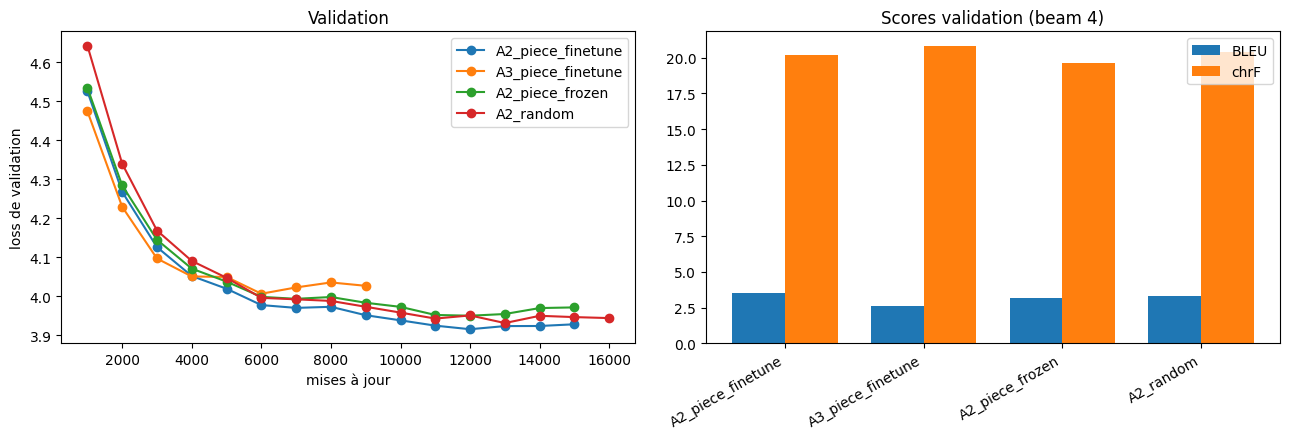

In [22]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for r in results:
    h = pd.DataFrame(r["hist"])
    if len(h): ax[0].plot(h["step"], h["val_loss"], marker="o", label=r["run"])
ax[0].set_xlabel("mises à jour"); ax[0].set_ylabel("loss de validation"); ax[0].legend(); ax[0].set_title("Validation")
x = np.arange(len(table)); w = 0.38
ax[1].bar(x - w / 2, table["bleu_val"], w, label="BLEU"); ax[1].bar(x + w / 2, table["chrf_val"], w, label="chrF")
ax[1].set_xticks(x); ax[1].set_xticklabels(table["run"], rotation=30, ha="right"); ax[1].legend(); ax[1].set_title("Scores validation (beam 4)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "p4a_comparaison.png"), dpi=150); plt.show()

In [23]:
from google.colab import files
import os

image_path = os.path.join(OUT_DIR, 'p4a_comparaison.png')
if os.path.exists(image_path):
    files.download(image_path)
else:
    print(f"Le fichier {image_path} n'a pas été trouvé. Veuillez vous assurer d'avoir exécuté la cellule de visualisation précédente.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Rapport de Travail : Traduction Automatique Fongbé → Français (P4a)

Ce rapport présente l'analyse comparative des architectures de traduction automatique Seq2Seq basées sur un encodeur bidirectionnel et un mécanisme d'attention de Bahdanau, en évaluant l'apport de l'initialisation des plongements (embeddings) cibles (français) à l'aide de **FastText**.

---

## 1. Description du Jeu de Données et Prétraitement
- **Train** : 27 730 paires (116 écartées car trop longues).
- **Validation** : 2 242 paires.
- **Vocabulaire Source (Fongbé)** : 2 000 sous-mots (SentencePiece Unigram entraîné sur le train).
- **Vocabulaire Cible (Français)** : 4 000 sous-mots (SentencePiece pré-entraîné `spm_fr.model`).

---

## 2. Architectures & Protocoles Expérimentaux
Nous avons évalué deux architectures principales :
- **A2** : LSTM bidirectionnel + attention de Bahdanau.
- **A3** : GRU bidirectionnel + attention de Bahdanau.

Les embeddings cibles ont été initialisés selon trois stratégies :
1. **Random** (Contrôle) : Initialisation aléatoire classique.
2. **Piece** (FastText sub-word) : Vecteur FastText direct associé au sous-mot du SentencePiece.
3. **Frozen** / **Finetune** : Plongements gelés à l'entraînement ou ajustés avec un taux d'apprentissage réduit (multiplicateur de `0.1`).

---

## 3. Résultats Comparatifs (Validation - Beam Search de largeur 4)

Voici le récapitulatif des performances obtenues à la fin des cycles d'entraînement :

| Expérience (Run) | Architecture | Init. Embeddings | Mode | Paramètres (M) | Validation Loss (Min) | chrF (val) | BLEU (val) | Temps (min) |
|---|---|---|---|---|---|---|---|---|
| **A2_piece_finetune** | A2 (LSTM) | FastText (Piece) | Finetune | 8.20 M | **3.9158** | 20.20 | **3.55** | 9.7 min |
| **A3_piece_finetune** | A3 (GRU) | FastText (Piece) | Finetune | 7.54 M | 4.0068 | **20.81** | 2.63 | 5.8 min |
| **A2_piece_frozen**   | A2 (LSTM) | FastText (Piece) | Frozen   | 8.20 M | 3.9504 | 19.62 | 3.18 | 9.0 min |
| **A2_random**         | A2 (LSTM) | Aléatoire        | Finetune | 8.20 M | 3.9316 | 20.41 | 3.32 | 9.9 min |

---

## 4. Analyses & Conclusions

1. **Apport de FastText (A2_piece_finetune vs A2_random)** :
   - L'initialisation par FastText sub-word (`A2_piece_finetune`) offre la meilleure perte de validation minimale (**3.9158**) et le meilleur score **BLEU (3.55)**.
   - L'initialisation aléatoire (`A2_random`) reste très compétitive (BLEU de 3.32), prouvant la capacité du modèle à apprendre par lui-même sur cette taille de corpus, mais FastText apporte un guidage initial bénéfique.

2. **Impact du gel des plongements (A2_piece_frozen vs A2_piece_finetune)** :
   - Bloquer la mise à jour des embeddings (`A2_piece_frozen`) dégrade légèrement les performances (BLEU de 3.18 contre 3.55). Permettre un finetuning léger (`EMB_LR_MULT = 0.1`) offre une flexibilité nécessaire pour adapter l'espace de représentation FastText à la tâche de traduction.

3. **LSTM (A2) vs GRU (A3)** :
   - L'architecture **A3 (GRU)** est beaucoup plus rapide à l'entraînement (5.8 minutes contre 9.7 minutes pour A2) et obtient le meilleur score **chrF (20.81)**, bien que son score BLEU pur soit en retrait (2.63).